# Figure 1b
Fixation location probability at $r=1$ and $r=5$.

In [1]:
import json

import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

from fixloc import style as S

d = json.load(open('data.json'))

In [2]:
POS = {
  0: (0.55, 1.55), 1: (2.45, 1.85), 2: (5.2, 1.3), 3: (0.0, 0.0), 4: (1.0, 0.0), 5: (2.0, 0.0), 6: (3.0, 0.0),
  7: (4.0, 0.0), 8: (0.0, -1.0), 9: (1.0, -1.0), 10: (2.0, -1.0), 11: (3.0, -1.0), 12: (4.9, -0.75),
}
MONITORED = {1: 3, 4: 4, 8: 5, 11: 6}
R = 0.2
two, one = [tuple(e) for e in d['two_way']], [tuple(e) for e in d['one_way']]


def regions(ax):
  box = 'round,pad=0.12,rounding_size=0.35'
  ax.add_patch(FancyBboxPatch((0.2, 1.15), 5.35, 1.0, boxstyle=box, facecolor=S.LPURPLE, alpha=0.5, lw=0, zorder=0))
  ax.add_patch(FancyBboxPatch((-0.32, -1.32), 5.55, 1.64, boxstyle=box, facecolor=S.LGREEN, alpha=0.5, lw=0, zorder=0))


def draw(ax, fills, origin=None):
  regions(ax)
  S.draw_graph(ax, POS, two, fills, R=R, one_way=one, shapes=MONITORED, gap=0.04, link_lw=0.8)
  if origin is not None:
    x, y = POS[origin]
    S.arrow(ax, (x - 0.62, y + 0.38), (x - 0.2 * 0.85 - 0.04, y + 0.1), color=S.ORIGIN, lw=1.0, scale=7)

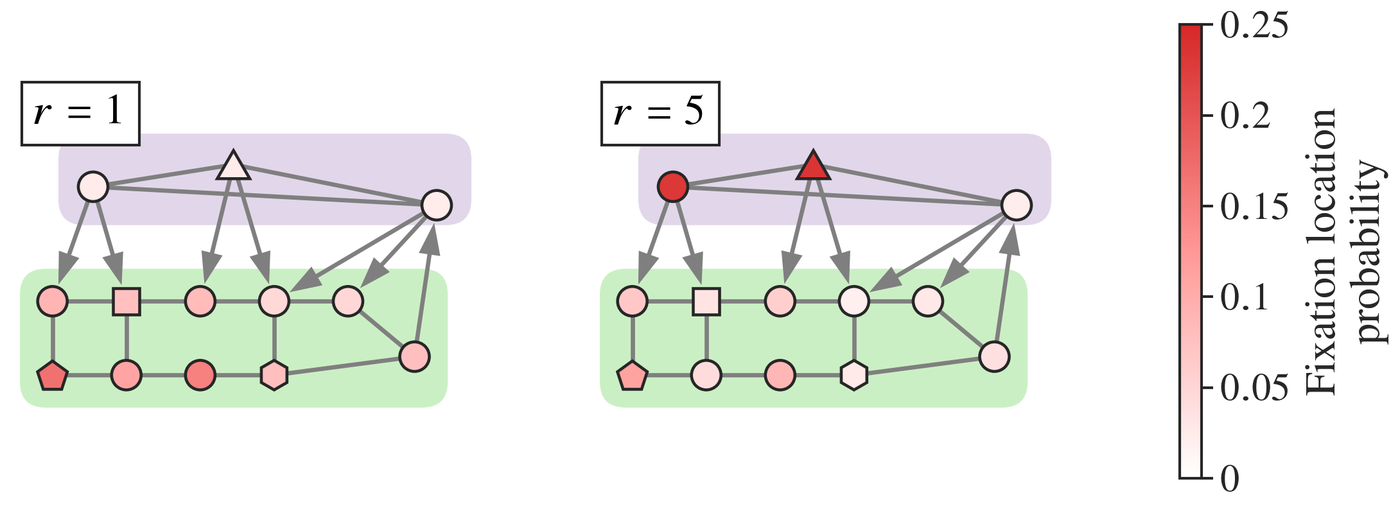

In [3]:
fig = plt.figure(figsize=(7.0, 3.1))
for k, r in enumerate(('1.0', '5.0')):
  ax = fig.add_axes([0.012 + 0.215 * k, 0.04, 0.2, 0.5])
  draw(ax, S.shade(S.CM_LAST, dict(enumerate(d['P_last'][r])), 0, 0.25))
  ax.set_xlim(-0.55, 6.75)
  ax.set_ylim(-1.5, 2.85)
  S.boxed(ax, -0.25, 2.8, r'$r=%g$' % float(r))
cax = fig.add_axes([0.445, 0.1, 0.008, 0.38])
ticks = [0, 0.05, 0.1, 0.15, 0.2, 0.25]
cb = S.colorbar(fig, cax, S.CM_LAST, 0, 0.25, ticks, 'Fixation location\nprobability')
cb.set_ticklabels([r'$%g$' % x for x in ticks])
S.save_panel(fig, 'b')